# 04 — Le capteur brut face à la station

Avant de corriger quoi que ce soit, on voulait comprendre **où, quand et pourquoi** le capteur brut se trompe. Ça nous
donne le point de départ du projet, et ça nous indique quelles variables pourront aider le modèle.

On regarde successivement :

1. le « avant » : quelle part des paires passe déjà les cibles de l'EPA sans correction ;
2. de quoi dépend l'erreur : humidité, saison, type de station, méthode de mesure, distance, âge du capteur ;
3. la forme de la relation : est-ce que l'erreur grandit avec la pollution ?
4. les écarts entre paires ;
5. le cas des paires « invérifiables ».

On travaille ici sur les **13,8 millions d'heures-paires utilisables** de la couche silver. Quelques termes qui
reviennent :

- le **capteur**, c'est la moyenne horaire des mesures PM2.5 valides du capteur citoyen ; la **référence**, c'est la
  valeur horaire validée de la station EEA ;
- une **heure-paire**, c'est une heure où capteur et référence ont tous les deux une valeur ;
- le **R²** mesure la part de la variation de la référence que le capteur reproduit (0 = rien, 1 = tout) ;
- la **RMSE** (erreur quadratique moyenne) est la racine de la moyenne des carrés des écarts capteur − référence, en
  µg/m³ ; elle pèse lourd sur les grosses erreurs. La **MAE** (erreur absolue moyenne) est la moyenne des écarts en
  valeur absolue ;
- une **paire invérifiable** est une paire dont les variations horaires ne suivent pas la station (notebook 03).

## 0. Préparation

On charge les heures utilisables, l'âge de chaque capteur (estimé au notebook 02) et les fonctions de mesure de
`src/aircalib/evaluation/metrics.py` (régression, cibles EPA, moyennes journalières), qui sont testées.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from aircalib.config import get_settings
from aircalib.evaluation.metrics import bin_label, daily_means, epa_targets, error_profile, regression_metrics
from aircalib.transform.humidity import age_class

SAMPLE = False
settings = get_settings().for_sample() if SAMPLE else get_settings()
E = settings.evaluation
PAIRS = settings.paths.silver / "pairs"
FIG_DIR = settings.paths.reports_dir / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(16)
pl.Config.set_tbl_width_chars(170)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

columns = [
    "pair_id",
    "sensor_id",
    "hour",
    "pm25_mean",
    "ref_pm25",
    "official_humidity",
    "official_temperature",
    "country",
    "distance_band",
    "distance_km",
    "station_type",
    "station_area",
    "method_class",
    "clock_flag",
    "local_reliable",
    "status",
]
registrations = pl.read_parquet(settings.paths.bronze / "reference" / "sensor_registrations.parquet")
season = {
    12: "hiver",
    1: "hiver",
    2: "hiver",
    3: "printemps",
    4: "printemps",
    5: "printemps",
    6: "été",
    7: "été",
    8: "été",
    9: "automne",
    10: "automne",
    11: "automne",
}
hours = (
    pl.read_parquet(PAIRS / "pair_hours.parquet", columns=columns)
    .filter(pl.col("status") == "ok")
    .drop("status")
    .rename({"pm25_mean": "sensor", "ref_pm25": "reference"})
    .join(registrations.select("sensor_id", "registered_by"), on="sensor_id", how="left")
    .with_columns(
        age_years=(pl.col("hour").dt.date() - pl.col("registered_by")).dt.total_days().clip(lower_bound=0)
        / 365.25,
        season=pl.col("hour").dt.month().replace_strict(season),
        year=pl.col("hour").dt.year(),
        humidity_bin=bin_label(pl.col("official_humidity"), E.humidity_bins, " %"),
        level_bin=bin_label(pl.col("reference"), E.level_bins, " µg/m³"),
    )
    .with_columns(age=age_class(pl.col("age_years"), settings.humidity.age_breaks_years))
)
pair_info = hours.group_by("pair_id").agg(
    pl.col("country", "distance_band", "distance_km", "station_type", "method_class", "clock_flag").first(),
    local_reliable=pl.col("local_reliable").mean(),
    humidity_median=pl.col("official_humidity").median(),
    age_years=pl.col("age_years").median(),
)
n_pairs, n_sensors = hours["pair_id"].n_unique(), hours["sensor_id"].n_unique()
print(f"{hours.height:,} heures-paires, {n_pairs} paires, {n_sensors} capteurs")

13,822,352 heures-paires, 1431 paires, 1382 capteurs


## 1. Le « avant » : les cibles EPA sans correction

Que vaut un capteur à 30 € tel quel, selon les critères d'un organisme de référence ? Pour chaque paire, on régresse le
capteur sur la référence (par moindres carrés) :

$$
\text{capteur} = a \cdot \text{référence} + b, \qquad
R^2 = \operatorname{corr}(\text{capteur}, \text{référence})^2, \qquad
\text{RMSE} = \sqrt{\tfrac{1}{n}\textstyle\sum (\text{capteur} - \text{référence})^2}
$$

avec $a$ la **pente** (1 si le capteur suit toute la variation de la référence), $b$ l'**ordonnée à l'origine** (son
biais quand la concentration est nulle, en µg/m³), $\operatorname{corr}$ la corrélation de Pearson et $n$ le nombre
d'heures. Les **cibles EPA** pour les capteurs de PM2.5 (Duvall et al., 2021) sont : $R^2 \ge 0{,}70$, une pente entre
0,65 et 1,35, une ordonnée entre −5 et +5 µg/m³ et une RMSE d'au plus 7 µg/m³. Une paire « passe » si elle tient les
quatre. L'EPA les définit sur des moyennes **journalières** ; on les calcule aussi en **horaire**. Une journée compte si
elle a au moins 18 heures valides, et une paire n'est évaluée que si elle a au moins 500 heures ou 30 jours.

In [2]:
targets = ["epa_r2", "epa_slope", "epa_intercept", "epa_rmse", "epa_all"]
hourly = (
    epa_targets(regression_metrics(hours, ["pair_id"]), E)
    .filter(pl.col("n") >= E.min_hours)
    .join(pair_info, on="pair_id")
)
days = daily_means(hours, ["pair_id"], E.daily_min_hours)
daily = (
    epa_targets(regression_metrics(days, ["pair_id"]), E)
    .filter(pl.col("n") >= E.min_days)
    .join(pair_info, on="pair_id")
)


def pass_rates(metrics: pl.DataFrame, by: list[str]) -> pl.DataFrame:
    return (
        metrics.group_by(by)
        .agg(
            *[(100 * pl.col(c).mean()).round(1).alias(c.replace("epa_", "%_")) for c in targets],
            paires=pl.len(),
            r2_médian=pl.col("r2").median().round(2),
            pente_médiane=pl.col("slope").median().round(2),
            ordonnée_médiane=pl.col("intercept").median().round(1),
            rmse_médian=pl.col("rmse").median().round(1),
        )
        .sort(by)
    )


before = pl.concat(
    [
        pass_rates(hourly, ["country", "distance_band"]).with_columns(résolution=pl.lit("horaire")),
        pass_rates(daily, ["country", "distance_band"]).with_columns(résolution=pl.lit("journalier")),
    ]
).select("résolution", pl.exclude("résolution"))
before

résolution,country,distance_band,%_r2,%_slope,%_intercept,%_rmse,%_all,paires,r2_médian,pente_médiane,ordonnée_médiane,rmse_médian
str,str,str,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64
"""horaire""","""DE""","""far""",36.9,38.8,91.3,52.8,19.1,680,0.62,0.58,-0.0,6.8
"""horaire""","""DE""","""near""",38.8,37.3,90.2,51.0,20.8,549,0.62,0.56,0.1,7.0
"""horaire""","""FR""","""far""",28.1,25.8,94.4,49.4,13.5,89,0.54,0.48,0.2,7.0
"""horaire""","""FR""","""near""",36.2,19.1,87.2,38.3,8.5,47,0.54,0.45,0.3,7.4
"""journalier""","""DE""","""far""",57.2,44.2,91.6,65.5,32.0,663,0.75,0.62,-0.3,5.6
"""journalier""","""DE""","""near""",58.8,41.8,91.1,63.5,32.7,529,0.76,0.59,-0.3,5.8
"""journalier""","""FR""","""far""",53.8,30.0,93.8,58.8,21.2,80,0.74,0.54,-0.3,5.8
"""journalier""","""FR""","""near""",51.2,16.3,83.7,67.4,11.6,43,0.71,0.48,0.0,6.2


Le même résultat résumé par pays, puis sans les paires dont l'horloge n'a pas pu être vérifiée, et chaque paire placée
dans le plan pente × R² :

shape: (4, 4)
┌────────────┬──────┬────────┬────────────────────────┐
│ résolution ┆ pays ┆ paires ┆ % passent les 4 cibles │
│ ---        ┆ ---  ┆ ---    ┆ ---                    │
│ str        ┆ str  ┆ i64    ┆ f64                    │
╞════════════╪══════╪════════╪════════════════════════╡
│ horaire    ┆ DE   ┆ 1229   ┆ 19.9                   │
│ horaire    ┆ FR   ┆ 136    ┆ 11.8                   │
│ journalier ┆ DE   ┆ 1192   ┆ 32.3                   │
│ journalier ┆ FR   ┆ 123    ┆ 17.9                   │
└────────────┴──────┴────────┴────────────────────────┘
sans les paires à l'horloge invérifiable : shape: (4, 3)
┌────────────┬──────┬────────────────────────┐
│ résolution ┆ pays ┆ % passent les 4 cibles │
│ ---        ┆ ---  ┆ ---                    │
│ str        ┆ str  ┆ f64                    │
╞════════════╪══════╪════════════════════════╡
│ horaire    ┆ DE   ┆ 23.7                   │
│ horaire    ┆ FR   ┆ 15.8                   │
│ journalier ┆ DE   ┆ 38.0              

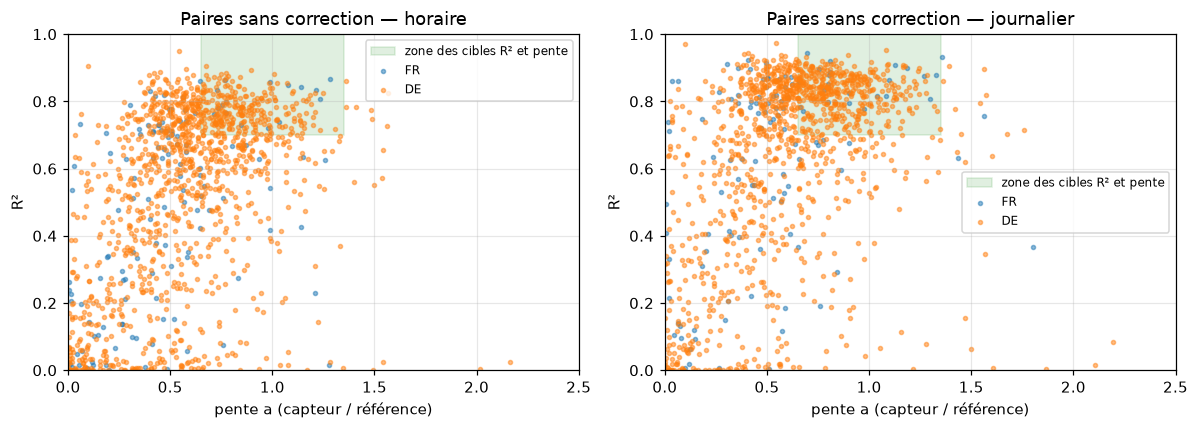

In [3]:
overall = pl.DataFrame(
    [
        {
            "résolution": name,
            "pays": country,
            "paires": frame.filter(pl.col("country") == country).height,
            "% passent les 4 cibles": round(
                100 * frame.filter(pl.col("country") == country)["epa_all"].mean(), 1
            ),
        }
        for name, frame in (("horaire", hourly), ("journalier", daily))
        for country in ("DE", "FR")
    ]
)
print(overall)
verified = pl.col("clock_flag") != "clock_unverifiable"
print(
    "sans les paires à l'horloge invérifiable :",
    pl.DataFrame(
        [
            {
                "résolution": name,
                "pays": country,
                "% passent les 4 cibles": round(
                    100 * frame.filter(verified, pl.col("country") == country)["epa_all"].mean(), 1
                ),
            }
            for name, frame in (("horaire", hourly), ("journalier", daily))
            for country in ("DE", "FR")
        ]
    ),
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, frame) in zip(axes, (("horaire", hourly), ("journalier", daily)), strict=True):
    lo, hi = E.epa_slope_range
    ax.add_patch(
        plt.Rectangle(
            (lo, E.epa_r2_min),
            hi - lo,
            1 - E.epa_r2_min,
            color="green",
            alpha=0.12,
            label="zone des cibles R² et pente",
        )
    )
    for (country,), part in frame.group_by("country", maintain_order=True):
        ax.scatter(part["slope"], part["r2"], s=7, alpha=0.5, label=country)
    ax.set_xlim(0, 2.5)
    ax.set_ylim(0, 1)
    ax.set_xlabel("pente a (capteur / référence)")
    ax.set_ylabel("R²")
    ax.set_title(f"Paires sans correction — {name}")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_avant_cibles_epa.png")

Et par type de station et méthode de mesure (en journalier) :

In [4]:
print(pass_rates(daily, ["country", "station_type"]))
pass_rates(daily, ["country", "method_class"])

shape: (6, 12)
┌─────────┬──────────────┬───────┬─────────┬─────────────┬────────┬───────┬────────┬───────────┬───────────────┬──────────────────┬─────────────┐
│ country ┆ station_type ┆ %_r2  ┆ %_slope ┆ %_intercept ┆ %_rmse ┆ %_all ┆ paires ┆ r2_médian ┆ pente_médiane ┆ ordonnée_médiane ┆ rmse_médian │
│ ---     ┆ ---          ┆ ---   ┆ ---     ┆ ---         ┆ ---    ┆ ---   ┆ ---    ┆ ---       ┆ ---           ┆ ---              ┆ ---         │
│ str     ┆ str          ┆ f64   ┆ f64     ┆ f64         ┆ f64    ┆ f64   ┆ u32    ┆ f64       ┆ f64           ┆ f64              ┆ f64         │
╞═════════╪══════════════╪═══════╪═════════╪═════════════╪════════╪═══════╪════════╪═══════════╪═══════════════╪══════════════════╪═════════════╡
│ DE      ┆ background   ┆ 58.3  ┆ 44.1    ┆ 91.8        ┆ 69.5   ┆ 33.4  ┆ 515    ┆ 0.75      ┆ 0.62          ┆ -0.1             ┆ 5.2         │
│ DE      ┆ industrial   ┆ 46.2  ┆ 30.8    ┆ 84.6        ┆ 50.0   ┆ 19.2  ┆ 26     ┆ 0.67      ┆ 0.55        

country,method_class,%_r2,%_slope,%_intercept,%_rmse,%_all,paires,r2_médian,pente_médiane,ordonnée_médiane,rmse_médian
str,str,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64
"""DE""","""beta""",67.3,55.8,92.3,71.2,46.2,52,0.79,0.67,-0.7,5.2
"""DE""","""nephelometry_beta""",26.6,41.0,90.8,72.8,14.5,173,0.62,0.6,0.0,5.4
"""DE""","""optical""",64.9,43.6,91.2,64.5,35.9,897,0.79,0.61,-0.4,5.7
"""DE""","""teom""",38.6,32.9,94.3,40.0,20.0,70,0.56,0.48,0.5,7.5
"""FR""","""beta""",30.0,20.0,86.7,50.0,13.3,30,0.56,0.44,-0.3,6.9
"""FR""","""optical""",60.8,27.5,88.2,56.9,23.5,51,0.78,0.5,0.0,6.4
"""FR""","""teom""",60.0,25.0,95.0,75.0,15.0,40,0.76,0.55,-0.1,5.2
"""FR""","""unknown""",50.0,50.0,100.0,100.0,0.0,2,0.74,0.64,0.0,5.0


Sans correction, **19,9 % des paires allemandes passent les quatre cibles en horaire et 32,3 % en journalier**. En France,
c'est 11,8 % et 17,9 %. Si on enlève les paires invérifiables, on monte à 23,7 % et 38,0 % en Allemagne.

C'est la **pente** qui coince le plus : sa médiane est entre 0,56 et 0,62, et seules 37 à 44 % des paires allemandes
ont une pente dans la cible. L'ordonnée passe environ 90 % du temps ; le R², 38 % du temps en horaire, mais près de 60 %
en journalier. La bande `far` ne fait pas pire que la bande `near` (19,1 % contre 20,8 % en horaire). Par méthode de
mesure (en journalier, en Allemagne), les stations à jauge bêta s'en sortent le mieux (46 %), devant le TEOM (20 %) et le
néphélomètre + bêta (14,5 %).

Le capteur brut ne voit donc qu'environ **60 %** de la référence : son principal défaut, c'est son gain, pas son bruit.
La moyenne sur 24 h efface une partie du bruit horaire, ce qui explique le meilleur R² en journalier. Et à ce stade,
l'erreur du capteur pèse bien plus que la distance. C'est ce chiffre « avant » qu'on reprend dans le README : le modèle
sera jugé sur le nombre de paires qu'il fait passer de l'autre côté.

## 2. De quoi dépend l'erreur du capteur brut ?

On cherche les conditions qui font varier l'erreur. Une variable qui la fait beaucoup bouger a des chances d'être utile
pour la correction ; une variable qui ne change rien n'apportera pas grand-chose au modèle.

Pour chaque tranche d'une condition, on calcule le **rapport médian** capteur / référence (1 = juste ; seulement quand les
deux dépassent 1 µg/m³), l'erreur médiane, la MAE, la RMSE et l'écart-type de $\ln(\text{capteur}/\text{référence})$,
une mesure de dispersion **relative** (en proportion, pas en µg/m³).

### 2.1 L'humidité officielle

country,humidity_bin,hours,pairs,reference_median,ratio_median,error_median,mae,rmse,log_ratio_std
str,str,u32,u32,f64,f64,f64,f64,f64,f64
"""DE""","""0. < 50 %""",1284308,1257,6.56,0.42,-3.78,7.95,36.78,0.82
"""DE""","""1. 50–60 %""",1162738,1265,6.45,0.44,-3.64,8.27,40.25,0.83
"""DE""","""2. 60–70 %""",1610966,1276,6.66,0.47,-3.54,8.36,41.27,0.82
"""DE""","""3. 70–80 %""",2333184,1277,6.96,0.51,-3.3,8.08,39.51,0.81
"""DE""","""4. 80–90 %""",3010794,1280,7.46,0.6,-2.86,7.95,38.46,0.8
"""DE""","""5. 90–95 %""",1719870,1274,7.93,0.69,-2.3,8.0,37.89,0.81
"""DE""","""6. ≥ 95 %""",1598856,1272,9.23,0.79,-1.95,8.84,39.56,0.84
"""FR""","""0. < 50 %""",98026,138,6.3,0.42,-3.59,6.01,19.18,0.67
"""FR""","""1. 50–60 %""",100464,143,5.9,0.41,-3.46,5.68,17.45,0.7


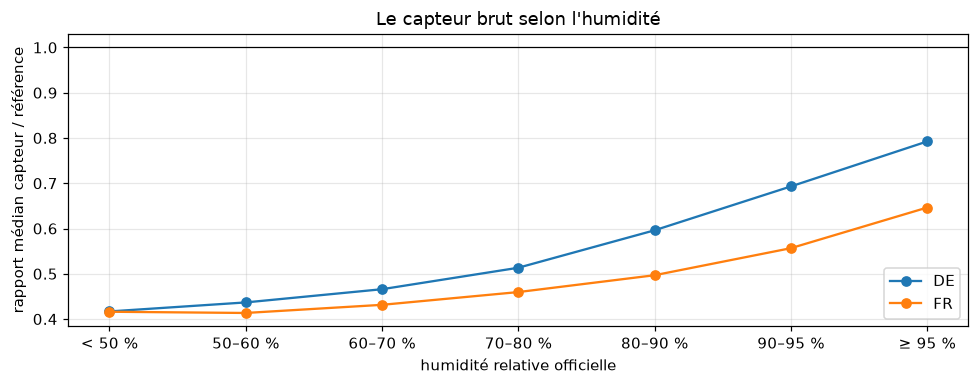

In [5]:
by_humidity = error_profile(hours, ["country", "humidity_bin"])
fig, ax = plt.subplots(figsize=(9, 3.6))
for (country,), part in by_humidity.group_by("country", maintain_order=True):
    ax.plot(part["humidity_bin"].str.slice(3), part["ratio_median"], marker="o", label=country)
ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("humidité relative officielle")
ax.set_ylabel("rapport médian capteur / référence")
ax.set_title("Le capteur brut selon l'humidité")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_rapport_humidite.png")
by_humidity.with_columns(pl.col(pl.Float64).round(2))

C'est la variable la plus marquante. En Allemagne, le rapport médian passe de **0,42** sous 50 % d'humidité à **0,79**
au-dessus de 95 %, et il monte régulièrement entre les deux (en France : de 0,42 à 0,65).

En air sec, le SDS011 sous-estime la référence de plus de moitié. En air humide, les particules gonflent d'eau, diffusent
plus de lumière, et le capteur « rattrape » la référence. Pour corriger, il faudra donc multiplier par environ 2,4 en air
sec et par environ 1,3 en air saturé : un facteur qui dépend de l'humidité, qu'on modélise au notebook 05.

### 2.2 Saison, type de station, méthode de mesure, distance

Le même profil d'erreur, condition par condition, en séparant l'Allemagne et la France :

In [6]:
tables = {}
for name, column in (
    ("saison", "season"),
    ("type de station", "station_type"),
    ("méthode de mesure", "method_class"),
    ("bande de distance", "distance_band"),
):
    tables[name] = (
        error_profile(hours, ["country", column])
        .rename({column: "tranche"})
        .with_columns(condition=pl.lit(name))
    )
profiles = pl.concat(tables.values()).select(
    "condition",
    "country",
    "tranche",
    "hours",
    "pairs",
    "reference_median",
    "ratio_median",
    "error_median",
    "mae",
    "rmse",
    "log_ratio_std",
)
profiles.with_columns(pl.col(pl.Float64).round(2))

condition,country,tranche,hours,pairs,reference_median,ratio_median,error_median,mae,rmse,log_ratio_std
str,str,str,u32,u32,f64,f64,f64,f64,f64,f64
"""saison""","""DE""","""automne""",2969176,1072,6.66,0.6,-2.56,7.81,39.7,0.86
"""saison""","""DE""","""hiver""",3225130,1223,9.41,0.62,-3.18,8.35,33.13,0.81
"""saison""","""DE""","""printemps""",3265793,1159,7.28,0.51,-3.44,8.81,40.97,0.85
"""saison""","""DE""","""été""",3260617,1114,6.48,0.51,-3.17,7.68,41.92,0.81
"""saison""","""FR""","""automne""",250217,106,6.4,0.49,-3.01,7.41,31.78,0.83
"""saison""","""FR""","""hiver""",296683,132,10.2,0.52,-4.41,9.14,31.14,0.78
"""saison""","""FR""","""printemps""",285439,125,5.8,0.46,-3.14,5.09,10.19,0.72
"""saison""","""FR""","""été""",269297,111,6.5,0.48,-3.29,5.51,18.16,0.68
"""type de station""","""DE""","""background""",5480574,549,6.65,0.6,-2.54,7.98,40.51,0.85


L'hiver étant plus humide, on s'est demandé si l'effet de la saison n'était pas en fait un effet de l'humidité. Voici le
rapport médian par saison **et** par tranche d'humidité, en Allemagne :

In [7]:
season_humidity = error_profile(hours.filter(pl.col("country") == "DE"), ["season", "humidity_bin"])
season_humidity.pivot(on="season", index="humidity_bin", values="ratio_median").sort(
    "humidity_bin"
).with_columns(pl.col(pl.Float64).round(2))

humidity_bin,automne,hiver,printemps,été
str,f64,f64,f64,f64
"""0. < 50 %""",0.44,0.43,0.39,0.44
"""1. 50–60 %""",0.45,0.46,0.42,0.44
"""2. 60–70 %""",0.47,0.49,0.46,0.46
"""3. 70–80 %""",0.51,0.53,0.51,0.5
"""4. 80–90 %""",0.6,0.62,0.6,0.56
"""5. 90–95 %""",0.7,0.71,0.7,0.65
"""6. ≥ 95 %""",0.81,0.81,0.78,0.73


- **Saison** : à chaque saison, le rapport monte avec l'humidité de la même façon (0,39–0,44 sous 50 %, 0,73–0,81
  au-dessus de 95 %). C'est donc bien l'humidité qui agit, pas la saison en elle-même.
- **Type de station** : le capteur sous-estime davantage près des stations trafic (0,52 contre 0,60 en fond urbain). La
  station en bord de route capte des particules de combustion que le capteur, un peu plus loin, ne voit pas.
- **Méthode de mesure** : des rapports proches (0,53 à 0,60), mais des dispersions différentes.
- **Distance** : le même rapport médian (0,55) en `near` et en `far`, mais une RMSE plus forte en `far` (44,6 contre
  30,6 µg/m³), tirée par quelques capteurs aberrants (section 4).
- Presque partout, **la RMSE vaut plusieurs fois la MAE** (jusqu'à 5 fois) : l'erreur quadratique est dominée par une
  minorité d'heures et de paires extrêmes.

On retient l'humidité officielle, le type de station et la méthode de mesure comme variables du modèle.

### 2.3 L'âge du capteur : y a-t-il une dérive ?

On voulait savoir si un capteur se dégrade avec le temps. Deux façons de regarder : le rapport médian selon l'âge du
capteur au moment de la mesure, et, **à l'intérieur de chaque paire**, la comparaison du rapport de 2025 avec celui de
2024 (pour les paires qui ont au moins 1 000 heures chaque année). Comparer des capteurs d'âges différents mélange l'âge,
le quartier et l'installation ; suivre le même capteur dans le temps isole vraiment la dérive.

shape: (10, 10)
┌─────────┬─────┬─────────┬───────┬──────────────────┬──────────────┬──────────────┬───────┬───────┬───────────────┐
│ country ┆ age ┆ hours   ┆ pairs ┆ reference_median ┆ ratio_median ┆ error_median ┆ mae   ┆ rmse  ┆ log_ratio_std │
│ ---     ┆ --- ┆ ---     ┆ ---   ┆ ---              ┆ ---          ┆ ---          ┆ ---   ┆ ---   ┆ ---           │
│ str     ┆ str ┆ u32     ┆ u32   ┆ f64              ┆ f64          ┆ f64          ┆ f64   ┆ f64   ┆ f64           │
╞═════════╪═════╪═════════╪═══════╪══════════════════╪══════════════╪══════════════╪═══════╪═══════╪═══════════════╡
│ DE      ┆ 1-2 ┆ 886453  ┆ 217   ┆ 7.37             ┆ 0.49         ┆ -3.78        ┆ 5.75  ┆ 12.32 ┆ 0.67          │
│ DE      ┆ 2-4 ┆ 1890933 ┆ 371   ┆ 7.2              ┆ 0.51         ┆ -3.41        ┆ 6.18  ┆ 16.92 ┆ 0.75          │
│ DE      ┆ 4-6 ┆ 4072218 ┆ 711   ┆ 7.3              ┆ 0.55         ┆ -3.14        ┆ 11.01 ┆ 56.16 ┆ 0.94          │
│ DE      ┆ <1  ┆ 1077231 ┆ 261   ┆ 7.29        

médiane,q10,q90,part_plus_20pct
f64,f64,f64,f64
1.006,0.801,1.253,0.284


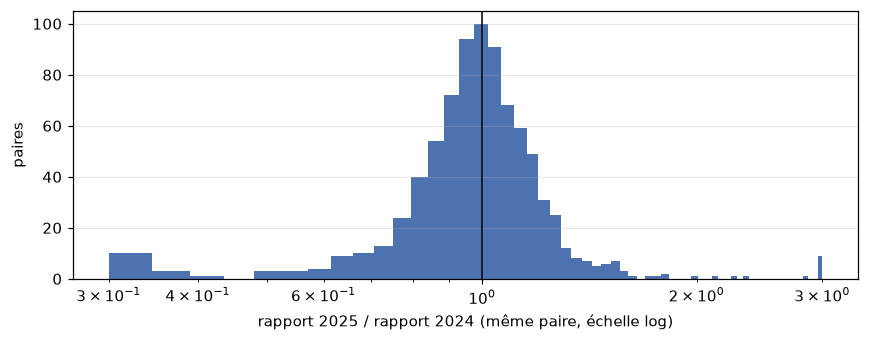

In [8]:
print(error_profile(hours, ["country", "age"]).with_columns(pl.col(pl.Float64).round(2)))
yearly = (
    hours.filter((pl.col("reference") > 1) & (pl.col("sensor") > 1))
    .group_by("pair_id", "year")
    .agg(ratio=(pl.col("sensor") / pl.col("reference")).median(), n=pl.len())
    .filter(pl.col("n") >= 1000)
    .pivot(on="year", index="pair_id", values="ratio")
    .drop_nulls()
    .with_columns(change=pl.col("2025") / pl.col("2024"))
    .join(pair_info.select("pair_id", "country", "age_years"), on="pair_id")
)
print(f"paires suivies sur les deux années : {yearly.height}")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(yearly["change"].clip(0.3, 3), bins=60, color="#4C72B0")
ax.axvline(1, color="k", lw=1)
ax.set_xscale("log")
ax.set_xlabel("rapport 2025 / rapport 2024 (même paire, échelle log)")
ax.set_ylabel("paires")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_derive_annuelle.png")
yearly.select(
    médiane=pl.col("change").median().round(3),
    q10=pl.col("change").quantile(0.1).round(3),
    q90=pl.col("change").quantile(0.9).round(3),
    part_plus_20pct=((pl.col("change") > 1.2) | (pl.col("change") < 1 / 1.2)).mean().round(3),
)

Pour les 830 paires suivies sur les deux ans, le rapport 2025 / 2024 a une médiane de **1,006**, mais **28 % des paires
changent de plus de 20 %** d'une année sur l'autre. Les capteurs de plus de 6 ans lisent un peu plus haut (rapport 0,61,
contre 0,49 la première année), et ceux de 4 à 6 ans ont la RMSE la plus forte (56 µg/m³).

Pas de dérive moyenne, donc, mais beaucoup d'instabilité d'un capteur à l'autre (encrassement, prise d'air déplacée,
remplacement non déclaré…). L'âge devient une variable candidate, et on testera au notebook 07 un modèle appris sur 2024
et appliqué à 2025.

## 3. La forme de la relation

Est-ce que l'erreur grandit avec la pollution ? Si l'erreur **absolue** augmente mais que l'erreur **relative** reste
stable, c'est que l'erreur est **multiplicative** : le capteur lit à peu près une fraction fixe de la référence.

Pour le vérifier, on calcule le rapport médian, l'erreur absolue et la dispersion relative par tranche de niveau de la
référence, et on trace le nuage capteur contre référence en échelle logarithmique.

country,level_bin,hours,pairs,reference_median,ratio_median,error_median,mae,rmse,log_ratio_std
str,str,u32,u32,f64,f64,f64,f64,f64,f64
"""DE""","""0. < 5 µg/m³""",3741509,1276,3.39,0.62,-1.49,5.83,40.81,0.94
"""DE""","""1. 5–10 µg/m³""",4766749,1280,7.0,0.5,-3.64,7.42,39.85,0.8
"""DE""","""2. 10–15 µg/m³""",2204197,1280,12.0,0.55,-5.69,9.09,36.62,0.76
"""DE""","""3. 15–25 µg/m³""",1472563,1270,18.21,0.6,-7.84,11.61,36.63,0.77
"""DE""","""4. 25–50 µg/m³""",495967,1249,30.22,0.61,-12.61,16.66,34.97,0.79
"""DE""","""5. ≥ 50 µg/m³""",39731,1095,56.36,0.5,-29.0,34.83,48.69,0.93
"""FR""","""0. < 5 µg/m³""",359222,143,3.3,0.55,-1.6,3.4,21.2,0.79
"""FR""","""1. 5–10 µg/m³""",392935,144,7.0,0.45,-3.94,5.75,24.25,0.67
"""FR""","""2. 10–15 µg/m³""",174828,145,11.9,0.48,-6.78,8.39,25.73,0.71


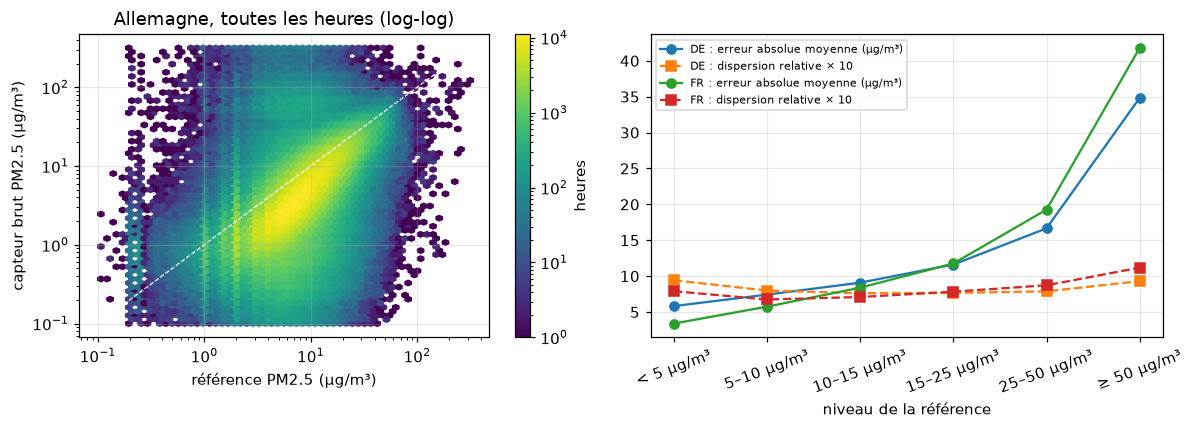

In [9]:
by_level = error_profile(hours, ["country", "level_bin"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
de = hours.filter(pl.col("country") == "DE", pl.col("sensor") > 0.1, pl.col("reference") > 0.1).sample(
    n=min(2_000_000, hours.height), seed=0
)
hb = axes[0].hexbin(
    de["reference"],
    de["sensor"],
    gridsize=60,
    bins="log",
    xscale="log",
    yscale="log",
    cmap="viridis",
    extent=(-1, 2.5, -1, 2.5),
)
axes[0].plot([0.1, 300], [0.1, 300], color="w", lw=0.8, ls="--")
axes[0].set_xlabel("référence PM2.5 (µg/m³)")
axes[0].set_ylabel("capteur brut PM2.5 (µg/m³)")
axes[0].set_title("Allemagne, toutes les heures (log-log)")
fig.colorbar(hb, ax=axes[0], label="heures")
for (country,), part in by_level.group_by("country", maintain_order=True):
    axes[1].plot(
        part["level_bin"].str.slice(3),
        part["mae"],
        marker="o",
        label=f"{country} : erreur absolue moyenne (µg/m³)",
    )
    axes[1].plot(
        part["level_bin"].str.slice(3),
        10 * part["log_ratio_std"],
        marker="s",
        ls="--",
        label=f"{country} : dispersion relative × 10",
    )
axes[1].set_xlabel("niveau de la référence")
axes[1].legend(fontsize=7)
axes[1].tick_params(axis="x", labelrotation=20)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_forme_relation.png")
by_level.with_columns(pl.col(pl.Float64).round(2))

Le rapport médian reste entre 0,5 et 0,6 sur toute la gamme (0,62 sous 5 µg/m³, 0,61 entre 25 et 50 µg/m³), alors que
l'erreur **absolue** explose : −1,5 µg/m³ en médiane sous 5 µg/m³, −29 µg/m³ au-dessus de 50 µg/m³ (la MAE passe de 5,8 à
34,8). La dispersion **relative**, elle, reste à peu près constante (entre 0,76 et 0,94). Sur le graphique log-log, le
nuage forme une bande droite parallèle à la diagonale, juste décalée vers le bas.

La relation est donc proportionnelle et l'erreur multiplicative. En µg/m³, les quelques heures très polluées
domineraient l'erreur quadratique d'un modèle. On avait deux options pour la cible du modèle, le logarithme ($\ln$ de la
référence) ou les µg/m³ ; on les a comparées sur les mêmes plis au notebook 06, et on a finalement gardé les µg/m³, parce
que les cibles EPA sont exprimées en µg/m³.

## 4. Les écarts entre paires

Est-ce que quelques paires concentrent l'erreur, et peut-on comprendre pourquoi ? On regarde la distribution des métriques
horaires par paire, puis on compare les **10 % de paires les plus mauvaises** (RMSE la plus forte) aux autres : pays, type
de station, méthode, bande, statut d'horloge, âge…

In [10]:
per_pair = hourly.with_columns(log_slope=pl.col("slope").log().abs())
print(
    per_pair.select(
        *[
            pl.col(c).quantile(q).round(2).alias(f"{c}_q{int(q * 100)}")
            for c in ("r2", "slope", "rmse")
            for q in (0.1, 0.5, 0.9)
        ]
    )
)
worst = per_pair["rmse"].quantile(0.9)
per_pair = per_pair.with_columns(
    groupe=pl.when(pl.col("rmse") >= worst).then(pl.lit("10 % les pires")).otherwise(pl.lit("autres"))
)
composition = per_pair.group_by("groupe").agg(
    paires=pl.len(),
    rmse_médian=pl.col("rmse").median().round(1),
    référence_moyenne=pl.col("mean_reference").median().round(1),
    pente_médiane=pl.col("slope").median().round(2),
    pct_France=(100 * (pl.col("country") == "FR").mean()).round(1),
    pct_trafic=(100 * (pl.col("station_type") == "traffic").mean()).round(1),
    pct_far=(100 * (pl.col("distance_band") == "far").mean()).round(1),
    pct_TEOM=(100 * (pl.col("method_class") == "teom").mean()).round(1),
    pct_horloge_invérifiable=(100 * (pl.col("clock_flag") == "clock_unverifiable").mean()).round(1),
    humidité_médiane=pl.col("humidity_median").median().round(1),
    pct_sonde_fiable=(100 * pl.col("local_reliable").median()).round(1),
    âge_médian=pl.col("age_years").median().round(1),
)
composition

shape: (1, 9)
┌────────┬────────┬────────┬───────────┬───────────┬───────────┬──────────┬──────────┬──────────┐
│ r2_q10 ┆ r2_q50 ┆ r2_q90 ┆ slope_q10 ┆ slope_q50 ┆ slope_q90 ┆ rmse_q10 ┆ rmse_q50 ┆ rmse_q90 │
│ ---    ┆ ---    ┆ ---    ┆ ---       ┆ ---       ┆ ---       ┆ ---      ┆ ---      ┆ ---      │
│ f64    ┆ f64    ┆ f64    ┆ f64       ┆ f64       ┆ f64       ┆ f64      ┆ f64      ┆ f64      │
╞════════╪════════╪════════╪═══════════╪═══════════╪═══════════╪══════════╪══════════╪══════════╡
│ 0.03   ┆ 0.62   ┆ 0.8    ┆ 0.1       ┆ 0.56      ┆ 0.98      ┆ 4.25     ┆ 6.93     ┆ 15.63    │
└────────┴────────┴────────┴───────────┴───────────┴───────────┴──────────┴──────────┴──────────┘


groupe,paires,rmse_médian,référence_moyenne,pente_médiane,pct_France,pct_trafic,pct_far,pct_TEOM,pct_horloge_invérifiable,humidité_médiane,pct_sonde_fiable,âge_médian
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""autres""",1228,6.5,9.1,0.57,9.9,52.4,56.8,8.3,10.3,79.0,0.0,4.9
"""10 % les pires""",137,41.1,9.4,0.34,10.2,54.0,52.6,9.5,78.8,80.0,0.0,5.5


Puis les corrélations de rang (Spearman, qui regarde si deux variables montent ensemble sans supposer de relation
linéaire) entre les caractéristiques d'une paire et sa RMSE, et la liste des 12 pires paires :

In [11]:
drivers = ["mean_reference", "humidity_median", "distance_km", "age_years", "local_reliable"]
spearman = pl.DataFrame(
    [
        {
            "variable": v,
            "corr_rang_avec_rmse": per_pair.select(pl.corr(v, "rmse", method="spearman")).item(),
            "corr_rang_avec_|ln pente|": per_pair.select(pl.corr(v, "log_slope", method="spearman")).item(),
            "corr_rang_avec_r2": per_pair.select(pl.corr(v, "r2", method="spearman")).item(),
        }
        for v in drivers
    ]
).with_columns(pl.col(pl.Float64).round(2))
print(spearman)
per_pair.sort("rmse", descending=True).select(
    "pair_id",
    "country",
    "station_type",
    "method_class",
    "distance_band",
    "n",
    "mean_reference",
    "mean_sensor",
    "slope",
    "r2",
    "rmse",
    "clock_flag",
).head(12).with_columns(pl.col(pl.Float64).round(2))

shape: (5, 4)
┌─────────────────┬─────────────────────┬───────────────────────────┬───────────────────┐
│ variable        ┆ corr_rang_avec_rmse ┆ corr_rang_avec_|ln pente| ┆ corr_rang_avec_r2 │
│ ---             ┆ ---                 ┆ ---                       ┆ ---               │
│ str             ┆ f64                 ┆ f64                       ┆ f64               │
╞═════════════════╪═════════════════════╪═══════════════════════════╪═══════════════════╡
│ mean_reference  ┆ 0.37                ┆ 0.01                      ┆ 0.09              │
│ humidity_median ┆ -0.02               ┆ -0.01                     ┆ -0.07             │
│ distance_km     ┆ 0.0                 ┆ -0.0                      ┆ -0.03             │
│ age_years       ┆ -0.02               ┆ -0.12                     ┆ -0.03             │
│ local_reliable  ┆ 0.03                ┆ 0.07                      ┆ 0.05              │
└─────────────────┴─────────────────────┴───────────────────────────┴─────────────────

pair_id,country,station_type,method_class,distance_band,n,mean_reference,mean_sensor,slope,r2,rmse,clock_flag
str,str,str,str,str,u32,f64,f64,f64,f64,f64,str
"""28904-1""","""DE""","""background""","""optical""","""far""",11387,8.76,643.11,2.81,0.01,672.89,"""clock_unverifiable"""
"""27740-1""","""DE""","""traffic""","""optical""","""far""",9923,10.1,579.3,3.9,0.01,636.97,"""clock_unverifiable"""
"""7887-1""","""DE""","""background""","""optical""","""far""",2054,6.68,424.41,-14.57,0.06,509.68,"""clock_unverifiable"""
"""20486-1""","""DE""","""traffic""","""optical""","""near""",15547,8.22,196.45,-9.35,0.05,346.37,"""clock_unverifiable"""
"""26307-1""","""DE""","""traffic""","""optical""","""near""",4614,8.73,233.89,-5.2,0.07,264.25,"""clock_unverifiable"""
"""24857-1""","""DE""","""traffic""","""optical""","""far""",16221,7.86,189.26,1.17,0.0,261.04,"""clock_unverifiable"""
"""31974-1""","""FR""","""traffic""","""teom""","""far""",4848,7.51,136.37,11.18,0.09,246.65,"""clock_unverifiable"""
"""2558-1""","""DE""","""background""","""optical""","""far""",14010,8.98,77.68,2.01,0.0,204.73,"""clock_unverifiable"""
"""30265-1""","""DE""","""background""","""optical""","""near""",15218,7.07,146.29,-0.92,0.0,187.33,"""clock_unverifiable"""


La RMSE horaire médiane est de 6,9 µg/m³, mais 10 % des paires dépassent 15,6 µg/m³. Et surtout, **79 % des pires paires
ont une horloge « invérifiable »**, contre 10 % des autres. Certains capteurs affichent 190 à 640 µg/m³ en moyenne pour 7
à 11 µg/m³ réels. Ni le type de station, ni la distance, ni l'humidité moyenne du site, ni l'âge du capteur ne distinguent
les pires paires (corrélations de rang proches de 0) ; seule la pollution moyenne du site joue un peu (0,37 avec la
RMSE).

Les pires paires ne sont donc pas des problèmes d'heure : ce sont des capteurs qui ne suivent pas du tout la référence.
Aucune règle physique ne les arrête (leurs valeurs restent dans la plage du SDS011), mais le contrôle d'horloge, qui
vérifie si les variations suivent la station, les avait déjà repérés.

## 5. Les paires « invérifiables » face aux paires vérifiées

Que faire des paires dont l'horloge n'a pas pu être vérifiée ? On compare leurs métriques et leur composition à celles des
paires vérifiées (`ok`) et des paires des stations TEOM (`instrument_lag`).

In [12]:
per_pair.join(daily.select("pair_id", epa_daily="epa_all"), on="pair_id", how="left").group_by(
    "clock_flag"
).agg(
    paires=pl.len(),
    heures=pl.col("n").sum(),
    r2_médian=pl.col("r2").median().round(2),
    pente_médiane=pl.col("slope").median().round(2),
    rmse_médian=pl.col("rmse").median().round(1),
    pct_epa_horaire=(100 * pl.col("epa_all").mean()).round(1),
    pct_epa_journalier=(100 * pl.col("epa_daily").mean()).round(1),
    pct_far=(100 * (pl.col("distance_band") == "far").mean()).round(1),
    distance_médiane_km=pl.col("distance_km").median().round(2),
    pct_trafic=(100 * (pl.col("station_type") == "traffic").mean()).round(1),
    pct_France=(100 * (pl.col("country") == "FR").mean()).round(1),
).sort("clock_flag")

clock_flag,paires,heures,r2_médian,pente_médiane,rmse_médian,pct_epa_horaire,pct_epa_journalier,pct_far,distance_médiane_km,pct_trafic,pct_France
str,u32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""clock_unverifiable""",235,2308599,0.03,0.17,14.1,0.0,1.8,57.4,1.73,54.9,14.9
"""instrument_lag""",17,191844,0.59,0.58,7.7,17.6,41.2,52.9,1.73,82.4,5.9
"""ok""",1113,11309342,0.68,0.6,6.3,23.1,36.8,56.2,1.67,51.6,9.0


Parmi les paires invérifiables qui ont au moins 500 heures (235 paires, 2,3 millions d'heures), le R² médian est de
**0,03**, la pente médiane de 0,17, la RMSE médiane de 14,1 µg/m³, et **aucune** ne passe les cibles EPA en horaire
(1,8 % en journalier), contre 23,1 % et 36,8 % pour les paires vérifiées. Pourtant, leur composition est la même (57 % en
bande `far`, 55 % près d'une station trafic). Les paires TEOM, elles, ressemblent aux paires vérifiées (R² 0,59, 41 %
passent en journalier).

Ce n'est donc ni une question de distance ni une question de type de station : c'est le capteur. Les paires
invérifiables sont, pour l'essentiel, des capteurs défectueux. Au passage, ça confirme qu'on a eu raison de garder les
stations TEOM.

Pour ces paires, on avait le choix entre les garder partout, les supprimer, ou les exclure seulement de l'apprentissage.
On a choisi (au feu vert de l'étape 5) de les **exclure de l'apprentissage** (on n'apprend pas sur des paires qu'on n'a
pas pu vérifier), tout en les **gardant pour l'évaluation**.

> **Vérification.** Chaque résultat sera donc donné deux fois : sur les « paires saines » et sur « toutes les paires ».
> Ne montrer que les saines serait trop optimiste, puisqu'un client ne sait pas à l'avance si son capteur est abîmé. Le
> prix de ce choix est faible : au notebook 06, on a vu qu'apprendre aussi sur ces paires n'aurait fait gagner que 3 paires
> sur 95 en horaire.

## Ce qu'il faut retenir

- Le « avant » : sans correction, **19,9 %** des paires allemandes passent les quatre cibles EPA en horaire et 32,3 % en
  journalier (11,8 % et 17,9 % en France). C'est la pente qui coince le plus : le capteur ne voit qu'environ 60 % de la
  référence.
- **L'humidité officielle est le premier levier** : le rapport capteur / référence passe de 0,42 en air sec à 0,79 en air
  saturé, quelle que soit la saison.
- L'erreur est multiplicative : le rapport reste entre 0,5 et 0,6, alors que l'erreur absolue va de −1,5 à −29 µg/m³
  selon le niveau de pollution.
- Pas de dérive moyenne (rapport 2025 / 2024 : 1,006), mais 28 % des capteurs changent de plus de 20 % d'une année à
  l'autre.
- Les paires invérifiables (R² médian 0,03, aucune ne passe en horaire) sont exclues de l'apprentissage mais gardées pour
  l'évaluation.